In [ ]:
!nvidia-smi

Wed Nov 18 13:13:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 비키니시티 머신러닝.zip to 비키니시티 머신러닝.zip


In [ ]:
from pathlib import Path
import zipfile
import json

zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_files) == 1, "데이터셋 ZIP 파일 하나를 업로드해 주세요."

data_dir = Path("/content/spongebob_coco")

with zipfile.ZipFile(zip_files[0]) as z:
    z.extractall(data_dir)

print("압축 해제 완료!\n")

for path in sorted(data_dir.rglob("*.json")):
    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    if "images" in data and "annotations" in data:
        print(f"라벨 파일: {path.relative_to(data_dir)}")
        print(f"이미지 수: {len(data['images'])}")
        print(f"박스 수: {len(data['annotations'])}")
        print("클래스:", data.get("categories", []))
        print()

압축 해제 완료!

라벨 파일: 비키니시티 머신러닝/test/_annotations.coco.json
이미지 수: 36
박스 수: 52
클래스: [{'id': 0, 'name': 'spongebob-characters', 'supercategory': 'none'}, {'id': 1, 'name': 'Patrick', 'supercategory': 'spongebob-characters'}, {'id': 2, 'name': 'SpongeBob', 'supercategory': 'spongebob-characters'}, {'id': 3, 'name': 'Squidward', 'supercategory': 'spongebob-characters'}]

라벨 파일: 비키니시티 머신러닝/train/_annotations.coco.json
이미지 수: 250
박스 수: 378
클래스: [{'id': 0, 'name': 'spongebob-characters', 'supercategory': 'none'}, {'id': 1, 'name': 'Patrick', 'supercategory': 'spongebob-characters'}, {'id': 2, 'name': 'SpongeBob', 'supercategory': 'spongebob-characters'}, {'id': 3, 'name': 'Squidward', 'supercategory': 'spongebob-characters'}]

라벨 파일: 비키니시티 머신러닝/valid/_annotations.coco.json
이미지 수: 71
박스 수: 109
클래스: [{'id': 0, 'name': 'spongebob-characters', 'supercategory': 'none'}, {'id': 1, 'name': 'Patrick', 'supercategory': 'spongebob-characters'}, {'id': 2, 'name': 'SpongeBob', 'supercategory': 'spongebob-c

In [ ]:
import json
import shutil
from pathlib import Path
from collections import Counter

source = Path("/content/spongebob_coco")
output = Path("/content/spongebob_yolo")

class_map = {1: 0, 2: 1, 3: 2}
class_names = ["patrick", "spongebob", "squidward"]

# 1. 세 폴더의 라벨 파일과 실제 사용된 클래스 확인
datasets = {}

for split in ["train", "valid", "test"]:
    matches = list(source.rglob(f"{split}/_annotations.coco.json"))
    assert len(matches) == 1, f"{split} 라벨 파일이 없거나 여러 개입니다."

    json_path = matches[0]
    data = json.loads(json_path.read_text(encoding="utf-8"))

    used_ids = Counter(a["category_id"] for a in data["annotations"])
    unexpected = set(used_ids) - set(class_map)

    assert not unexpected, (
        f"{split}에 예상 밖 클래스 번호가 있습니다: {unexpected}. "
        "출력 내용을 보내주세요."
    )

    datasets[split] = (json_path.parent, data)

# 2. 이미지 복사 및 박스 좌표 변환
for split, (folder, data) in datasets.items():
    image_dir = output / split / "images"
    label_dir = output / split / "labels"
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    annotations = {}
    for ann in data["annotations"]:
        annotations.setdefault(ann["image_id"], []).append(ann)

    box_count = 0

    for img in data["images"]:
        image_path = folder / img["file_name"]
        assert image_path.is_file(), f"이미지가 없습니다: {image_path}"

        width, height = img["width"], img["height"]
        assert width > 0 and height > 0, "이미지 크기가 잘못되었습니다."

        # 고유한 이미지 ID로 파일 이름 통일
        filename = f"{img['id']}{image_path.suffix.lower()}"
        shutil.copy2(image_path, image_dir / filename)

        lines = []
        for ann in annotations.get(img["id"], []):
            x, y, w, h = ann["bbox"]

            # 이미지 경계를 벗어나는 부분 정리
            x1 = max(0, min(width, x))
            y1 = max(0, min(height, y))
            x2 = max(0, min(width, x + w))
            y2 = max(0, min(height, y + h))

            assert x2 > x1 and y2 > y1, (
                f"잘못된 박스: {split}, 이미지 {img['id']}, {ann['bbox']}"
            )

            # YOLO: 클래스 번호, 중심 x/y, 너비/높이 (0~1)
            cx = (x1 + x2) / 2 / width
            cy = (y1 + y2) / 2 / height
            bw = (x2 - x1) / width
            bh = (y2 - y1) / height

            cls = class_map[ann["category_id"]]
            lines.append(f"{cls} {cx:.8f} {cy:.8f} {bw:.8f} {bh:.8f}")
            box_count += 1

        (label_dir / f"{img['id']}.txt").write_text(
            "\n".join(lines), encoding="utf-8"
        )

    print(f"{split}: 이미지 {len(data['images'])}장 / 박스 {box_count}개 변환 완료")

# 3. 학습용 설정 파일 생성
yaml_text = (
    f"path: {output}\n"
    "train: train/images\n"
    "val: valid/images\n"
    "test: test/images\n"
    "names:\n"
    "  0: patrick\n"
    "  1: spongebob\n"
    "  2: squidward\n"
)
(output / "data.yaml").write_text(yaml_text, encoding="utf-8")

print("\nYOLO 변환 완료!")
print("설정 파일:", output / "data.yaml")

train: 이미지 250장 / 박스 378개 변환 완료
valid: 이미지 71장 / 박스 109개 변환 완료
test: 이미지 36장 / 박스 52개 변환 완료

YOLO 변환 완료!
설정 파일: /content/spongebob_yolo/data.yaml


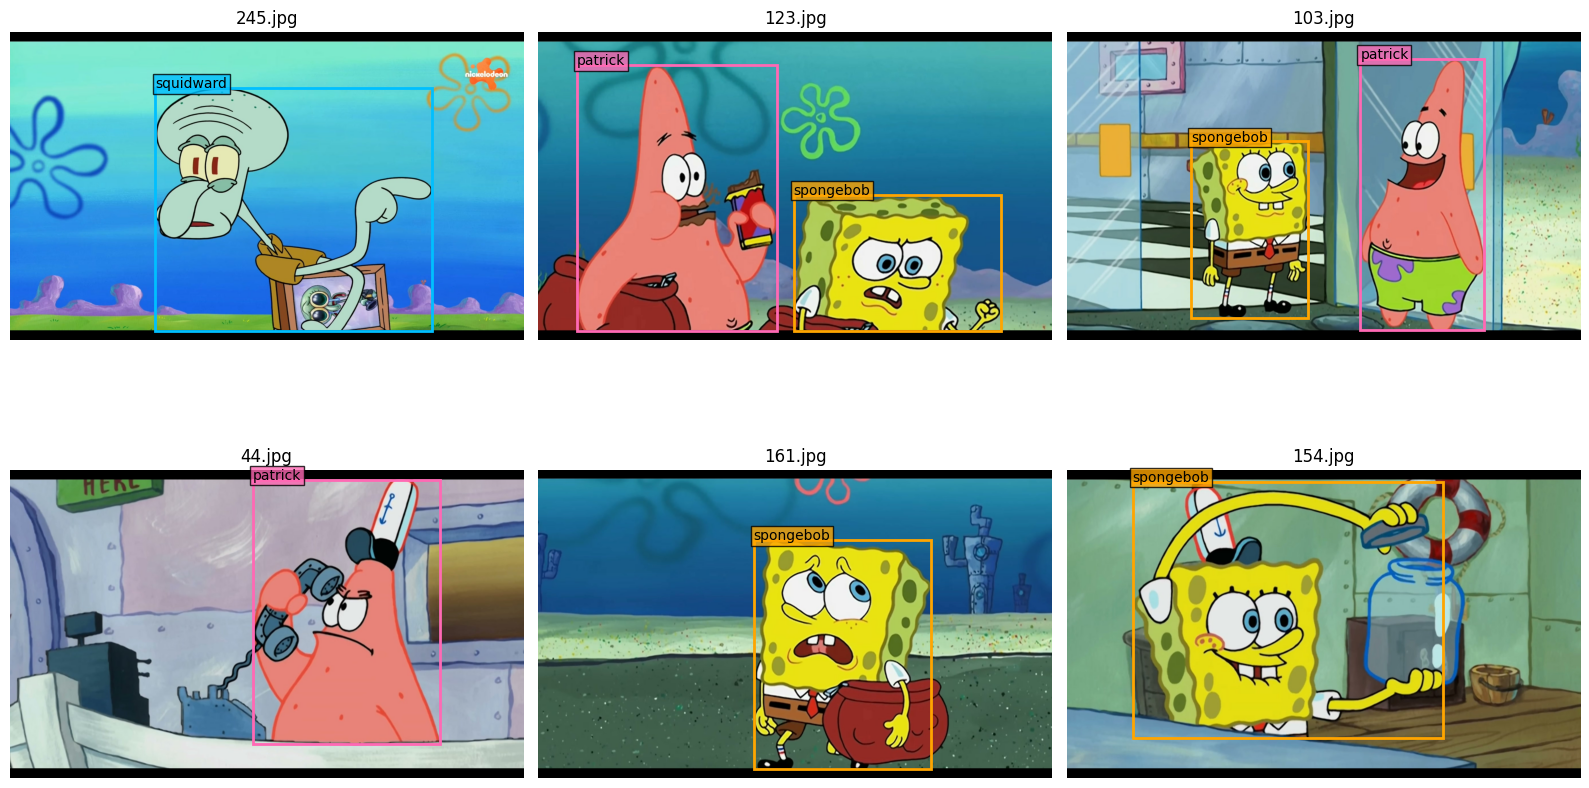

In [6]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

root = Path("/content/spongebob_yolo")
names = ["patrick", "spongebob", "squidward"]
colors = ["hotpink", "orange", "deepskyblue"]

images = sorted((root / "train/images").glob("*"))
samples = random.Random(42).sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, image_path in zip(axes.flat, samples):
    with Image.open(image_path) as img:
        ax.imshow(img)
        width, height = img.size

    label_path = root / "train/labels" / f"{image_path.stem}.txt"

    for line in label_path.read_text().splitlines():
        cls, cx, cy, bw, bh = map(float, line.split())
        cls = int(cls)

        x = (cx - bw / 2) * width
        y = (cy - bh / 2) * height
        w, h = bw * width, bh * height

        ax.add_patch(patches.Rectangle(
            (x, y), w, h,
            fill=False, edgecolor=colors[cls], linewidth=2
        ))
        ax.text(
            x, y, names[cls],
            color="black", fontsize=10,
            bbox=dict(facecolor=colors[cls], alpha=0.8, pad=2)
        )

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
%pip install -q ultralytics

In [8]:
import ultralytics
import torch

print("Ultralytics 버전:", ultralytics.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 버전: 8.4.215
GPU 사용 가능: True
GPU 이름: Tesla T4


In [9]:
from ultralytics import YOLO

# 일반 객체 이미지로 사전학습된 YOLOv8n 불러오기
model = YOLO("yolov8n.pt")

# 네 캐릭터 데이터로 추가 학습
results = model.train(
    data="/content/spongebob_yolo/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    device=0,
    workers=2,
    seed=42,
    project="/content/spongebob_runs",
    name="yolov8n_finetune",
    plots=True,
    save=True
)

print("학습 결과 폴더:", model.trainer.save_dir)
print("최적 모델 파일:", model.trainer.best)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/spongebob_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_finetune, nbs=64, nms=None, opset=None, optimi

In [10]:
import shutil
from google.colab import files

result_zip = shutil.make_archive(
    "/content/spongebob_training_results",
    "zip",
    root_dir="/content/spongebob_runs",
    base_dir="yolov8n_finetune"
)

files.download(result_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from ultralytics import YOLO
import json
from pathlib import Path

best_model = YOLO(
    "/content/spongebob_runs/yolov8n_finetune/weights/best.pt"
)

test_metrics = best_model.val(
    data="/content/spongebob_yolo/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    project="/content/spongebob_runs",
    name="test_evaluation",
    plots=True
)

scores = {
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map)
}

print("\n시험용 데이터 평가 결과")
for name, value in scores.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

save_dir = Path(test_metrics.save_dir)
(save_dir / "test_metrics.json").write_text(
    json.dumps(scores, indent=2),
    encoding="utf-8"
)
print("\n평가 결과 저장 위치:", save_dir)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3135.6±1368.6 MB/s, size: 230.6 KB)
val: Scanning /content/spongebob_yolo/test/labels... 36 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 2.1Kit/s 0.0s
val: New cache created: /content/spongebob_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.5it/s 1.2s
                   all         36         52       0.88      0.894      0.904      0.785
               patrick         19         20      0.939       0.95      0.988      0.883
             spongebob         17         17      0.973          1      0.995      0.885
             squidward         14         15      0.729      0.733       0.73      0.588
Speed: 1.6ms preprocess, 7.4ms inference, 0.0ms loss, 2.4ms postprocess per

In [12]:
from google.colab import files
from pathlib import Path

uploaded_video = files.upload()

video_path = str(Path(next(iter(uploaded_video))).resolve())
print("영상 업로드 완료:", video_path)

Saving 비키니시티.mp4 to 비키니시티.mp4
영상 업로드 완료: /content/비키니시티.mp4


In [13]:
from ultralytics import YOLO
from IPython.display import Video, display
import cv2
import subprocess
from pathlib import Path

model = YOLO(
    "/content/spongebob_runs/yolov8n_finetune/weights/best.pt"
)

# 원본 영상 정보 확인
cap = cv2.VideoCapture(video_path)
assert cap.isOpened(), "영상을 열지 못했어요. 업로드 경로를 확인해주세요."

fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()
assert fps > 0, "영상의 재생 속도를 읽지 못했어요."

output_dir = Path("/content/spongebob_video")
output_dir.mkdir(exist_ok=True)
raw_path = output_dir / "tracking_raw.mp4"
result_path = output_dir / "tracking_result.mp4"

# 한 프레임씩 탐지하고 추적
results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",
    conf=0.25,
    imgsz=640,
    device=0,
    stream=True,
    verbose=False
)

writer = None
frame_count = 0

try:
    for result in results:
        frame = result.plot()  # 박스, 이름, 신뢰도, 추적 ID 표시

        if writer is None:
            height, width = frame.shape[:2]
            writer = cv2.VideoWriter(
                str(raw_path),
                cv2.VideoWriter_fourcc(*"mp4v"),
                fps,
                (width, height)
            )
            assert writer.isOpened(), "결과 영상 저장을 시작하지 못했어요."

        writer.write(frame)
        frame_count += 1
finally:
    if writer is not None:
        writer.release()

assert frame_count > 0, "처리한 영상 프레임이 없어요."

# Colab에서 재생 가능한 MP4로 변환 (소리 제외)
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", str(raw_path),
    "-c:v", "libx264", "-pix_fmt", "yuv420p",
    "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2",
    "-movflags", "+faststart",
    "-an", str(result_path)
], check=True)

print(f"완료! 총 {frame_count}프레임 처리")
print("저장 위치:", result_path)
display(Video(str(result_path), embed=True, width=800))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 191ms
Prepared 1 package in 31ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

완료! 총 207프레임 처리
저장 위치: /content/spongebob_video/tracking_result.mp4


In [14]:
import subprocess
from google.colab import files

submission_video = "/content/spongebob_video/tracking_5sec.mp4"

subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", "/content/spongebob_video/tracking_result.mp4",
    "-t", "5",
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    "-an", submission_video
], check=True)

files.download(submission_video)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import shutil
from google.colab import files

evaluation_zip = shutil.make_archive(
    "/content/spongebob_test_evaluation",
    "zip",
    root_dir="/content/spongebob_runs",
    base_dir="test_evaluation"
)

files.download(evaluation_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>